In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy.stats import pearsonr, spearmanr
import ast, os, sys
sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import read_fasta, read_parrot_preds

In [2]:
# Parameters to make figures work better with illustrator 
import matplotlib 
# For higher resoltion figures
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams["font.family"] = "Helvetica"
plt.rcParams['pdf.fonttype'] = 42

In [3]:
seq_df = read_fasta('synthetics/synthetics_test_seqs.fasta')
with open('synthetics/synthetics_test_seqs.tsv', 'w+') as f:
    for i in seq_df.index:
        f.write(f"{i}\t{seq_df.loc[i, 'seq']}\n")

In [17]:
parrot_preds_all_six = read_parrot_preds('synthetics/synthetics_preds_parrot_all_six_model.csv')
parrot_preds_all_six

,name,sequence,preds
0,0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,"[0.5332423, 0.5388931, 0.5505405, 0.5644276, 0..."
1,1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,"[0.4889961, 0.4922967, 0.5013463, 0.5129704, 0..."
2,2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,"[0.6576298, 0.65728676, 0.65533376, 0.65538013..."
3,3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,"[0.6141509, 0.614229, 0.61264247, 0.6112419, 0..."
4,4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,"[0.5780696, 0.57572263, 0.57352376, 0.56840974..."
...,...,...,...
16765,16765,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,"[0.75610703, 0.7434072, 0.7621642, 0.76770574,..."
16766,16766,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,"[0.73728424, 0.7357984, 0.762568, 0.7883092, 0..."
16767,16767,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,"[0.42225128, 0.39522386, 0.41028717, 0.4180306..."
16768,16768,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,"[0.5503052, 0.54474545, 0.5731369, 0.58758, 0...."


In [18]:
parrot_preds_all_six_regression = read_parrot_preds('synthetics/synthetics_preds_parrot_all_six_model_regression.csv')
parrot_preds_all_six_regression

,name,sequence,preds
0,0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,"[0.368128, 0.4137964, 0.45841336, 0.49887425, ..."
1,1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,"[0.25879303, 0.28961417, 0.3217081, 0.3553555,..."
2,2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,"[0.3695771, 0.41016722, 0.44883344, 0.47138783..."
3,3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,"[0.3355673, 0.37285632, 0.40779608, 0.426631, ..."
4,4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,"[0.36561197, 0.40556484, 0.4447063, 0.46489868..."
...,...,...,...
16765,16765,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,"[0.81823206, 0.82833505, 0.84346485, 0.8710987..."
16766,16766,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,"[0.85125244, 0.8741324, 0.8997561, 0.91726923,..."
16767,16767,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,"[0.40681165, 0.40862244, 0.41186562, 0.4250107..."
16768,16768,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,"[0.53889, 0.55140793, 0.5732851, 0.6017201, 0...."


In [19]:
adpred_preds = pd.read_csv('synthetics/synthetics_test_seqs_53mer_ADpred_preds_dask.csv', index_col=0)
adhunter_ensemble_preds = pd.read_csv('synthetics/synthetics_test_seqs_ADhunter_ensemble_preds.csv', index_col=0)
adhunter_ensemble_preds = adhunter_ensemble_preds.rename(columns = {'seq' : 'sequence'})
adhunter_preds = pd.read_csv('synthetics/synthetics_test_seqs_ADHunter_preds_dask.csv', index_col=0)
paddle_preds = pd.read_csv('synthetics/synthetics_test_seqs_53mer_Paddle_preds_dask.csv', index_col=0) # This is no_SS (add SS!)
paddle_preds = paddle_preds.rename(columns = {'seq' : 'sequence'})
tada_preds = pd.read_csv('synthetics/synthetics_test_seqs_TADA_preds_dask.csv', index_col=0)

In [20]:
parrot_preds_all_six['parrot_max_value_all_six'] = [max([float(a) for a in ls]) for ls in (parrot_preds_all_six['preds'])]
parrot_preds_all_six['parrot_mean_value_all_six'] = [np.mean([float(a) for a in ls]) for ls in (parrot_preds_all_six['preds'])]

parrot_preds_all_six_regression['parrot_max_value_all_six'] = [max([float(a) for a in ls]) for ls in (parrot_preds_all_six_regression['preds'])]
parrot_preds_all_six_regression['parrot_mean_value_all_six'] = [np.mean([float(a) for a in ls]) for ls in (parrot_preds_all_six_regression['preds'])]

paddle_preds['paddle_max_value'] = [max(ast.literal_eval(ls)) for ls in (paddle_preds['paddle_preds'])]
paddle_preds['paddle_mean_value'] = [np.mean(ast.literal_eval(ls)) for ls in (paddle_preds['paddle_preds'])]

tada_preds['tada_max_value'] = [max(ast.literal_eval(ls)) for ls in (tada_preds['tada_preds'])]
tada_preds['tada_mean_value'] = [np.mean(ast.literal_eval(ls)) for ls in (tada_preds['tada_preds'])]

adpred_preds['adpred_max_value'] = [max(ast.literal_eval(ls)) for ls in (adpred_preds['adpred_preds'])]
adpred_preds['adpred_mean_value'] = [np.mean(ast.literal_eval(ls)) for ls in (adpred_preds['adpred_preds'])]

adhunter_preds['adhunter_max_value'] = [max(ast.literal_eval(ls)) for ls in (adhunter_preds['adhunter_preds'])]
adhunter_preds['adhunter_mean_value'] = [np.mean(ast.literal_eval(ls)) for ls in (adhunter_preds['adhunter_preds'])]

adhunter_ensemble_preds['adhunter_ensemble_max_value'] = [max(ast.literal_eval(ls)) for ls in (adhunter_ensemble_preds['adhunter_ensemble_preds'])]
adhunter_ensemble_preds['adhunter_ensemble_mean_value'] = [np.mean(ast.literal_eval(ls)) for ls in (adhunter_ensemble_preds['adhunter_ensemble_preds'])]

In [21]:
experimental = pd.read_csv('synthetics/Synthetics_Activities.csv')
experimental

,AAseq,Activity,StdDev,Activity_GFP,StdDev_GFP,Activity_mCherry,StdDev_mCherry
0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,0.473609,NaN,0.575642,NaN,468.881757,NaN
1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,0.903132,NaN,0.733105,NaN,312.143504,NaN
2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,3.868678,0.222749,3.061543,0.369973,240.421461,34.900357
3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,2.469731,0.256302,1.888136,0.463168,252.884922,50.010381
4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,1.236664,NaN,2.249856,NaN,440.446675,NaN
...,...,...,...,...,...,...,...
16765,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,5.990318,0.129122,6.290907,0.508324,161.573960,55.704165
16766,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,5.587220,0.645912,6.227913,0.048433,159.374865,NaN
16767,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,0.981382,NaN,-0.744936,NaN,109.030773,NaN
16768,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,3.257207,0.058277,2.900316,0.100772,250.454172,47.344796


In [22]:
# Extract corresponding sequence
paddle_preds['40mer_seq'] = paddle_preds['sequence'].str[-40:]
adpred_preds['40mer_seq'] = adpred_preds['sequence'].str[-40:]
adhunter_ensemble_preds['40mer_seq'] = adhunter_ensemble_preds['sequence'].str[-40:]

In [10]:
experimental

,AAseq,Activity,StdDev,Activity_GFP,StdDev_GFP,Activity_mCherry,StdDev_mCherry
0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,0.473609,NaN,0.575642,NaN,468.881757,NaN
1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,0.903132,NaN,0.733105,NaN,312.143504,NaN
2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,3.868678,0.222749,3.061543,0.369973,240.421461,34.900357
3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,2.469731,0.256302,1.888136,0.463168,252.884922,50.010381
4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,1.236664,NaN,2.249856,NaN,440.446675,NaN
...,...,...,...,...,...,...,...
16765,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,5.990318,0.129122,6.290907,0.508324,161.573960,55.704165
16766,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,5.587220,0.645912,6.227913,0.048433,159.374865,NaN
16767,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,0.981382,NaN,-0.744936,NaN,109.030773,NaN
16768,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,3.257207,0.058277,2.900316,0.100772,250.454172,47.344796


In [23]:
paddle_preds = paddle_preds.drop(columns = ['name'])
adpred_preds = adpred_preds.drop(columns = ['name'])
adhunter_preds = adhunter_preds.drop(columns = ['name']).rename(columns={'sequence' : '40mer_seq'})
adhunter_ensemble_preds = adhunter_ensemble_preds.drop(columns=['name'])
tada_preds = tada_preds.drop(columns=['name']).rename(columns={'sequence' : '40mer_seq'})
parrot_preds_all_six = parrot_preds_all_six.drop(columns=['name']).rename(columns={'sequence' : '40mer_seq'})
parrot_preds_all_six_regression = parrot_preds_all_six_regression.drop(columns=['name']).rename(columns={'sequence' : '40mer_seq'})
experimental = experimental.rename(columns={'AAseq' : '40mer_seq'})

In [24]:
all_merged = paddle_preds.merge(
                        experimental, on='40mer_seq').merge(
                            adpred_preds, on='40mer_seq').merge(
                                adhunter_preds, on='40mer_seq').merge(
                                    adhunter_ensemble_preds, on='40mer_seq').merge(
                                        tada_preds, on='40mer_seq').merge(
                                            parrot_preds_all_six, on='40mer_seq')
all_merged

,sequence_x,paddle_centers,paddle_preds,paddle_max_value,paddle_mean_value,40mer_seq,Activity,StdDev,Activity_GFP,StdDev_GFP,...,adhunter_ensemble_uncertainty,adhunter_ensemble_max_value,adhunter_ensemble_mean_value,tada_centers,tada_preds,tada_max_value,tada_mean_value,preds,parrot_max_value_all_six,parrot_mean_value_all_six
0,SHLATAGSTSSASMLDEEGLLLDEDTEVFSTAEAVSDEEALEDLFN...,[27.0],[5.932084],5.932084,5.932084,MLDEEGLLLDEDTEVFSTAEAVSDEEALEDLFNSQNLMSP,0.504222,0.400618,-0.031637,0.276409,...,[0.03885703533887863],-0.355279,-0.355279,[20.0],[0.6278114],0.627811,0.627811,"[0.6435172, 0.58707154, 0.5584144, 0.6137331, ...",0.694714,0.583114
1,SHLATAGSTSSASCFALFSDEDELEDDSDIEEISESFWAMELRMNL...,[27.0],[2.285699],2.285699,2.285699,CFALFSDEDELEDDSDIEEISESFWAMELRMNLESLDTIL,0.099781,0.025926,-0.509947,0.096310,...,[0.056527383625507355],0.149991,0.149991,[20.0],[0.59957534],0.599575,0.599575,"[0.65854174, 0.6282595, 0.611077, 0.58262247, ...",0.822906,0.634507
2,SHLATAGSTSSASRTDLHFDLQEEVDIGLDSFEADILDFAKTDKEF...,[27.0],[6.942725],6.942725,6.942725,RTDLHFDLQEEVDIGLDSFEADILDFAKTDKEFQSLLVKG,2.689859,0.345964,-0.043791,0.244942,...,[0.03492335230112076],0.237311,0.237311,[20.0],[0.58301306],0.583013,0.583013,"[0.6430211, 0.69725204, 0.701146, 0.6728465, 0...",0.702729,0.617054
3,SHLATAGSTSSASLDRLKELDDFDDHLLSSDVDEDSACYDFTFGLC...,[27.0],[3.865158],3.865158,3.865158,LDRLKELDDFDDHLLSSDVDEDSACYDFTFGLCFSKLFDG,1.184397,0.152515,1.042259,0.110737,...,[0.09733191132545471],0.441110,0.441110,[20.0],[0.6014871],0.601487,0.601487,"[0.64335287, 0.6413197, 0.64104915, 0.6676777,...",0.874157,0.683322
4,SHLATAGSTSSASSDEQLELSEKQSYSDLDYKAEGLDSFPDAVQLW...,[27.0],[1.3277686],1.327769,1.327769,SDEQLELSEKQSYSDLDYKAEGLDSFPDAVQLWFPFLLDI,5.365347,0.031940,2.403262,1.336788,...,[0.020473340526223183],0.271435,0.271435,[20.0],[0.5974743],0.597474,0.597474,"[0.5969763, 0.59480494, 0.5915419, 0.5670354, ...",0.759883,0.573996
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16765,SHLATAGSTSSASIDHPSSSSMLSGELLFDGCWLETTDGSEFLSTN...,[27.0],[8.633421],8.633421,8.633421,IDHPSSSSMLSGELLFDGCWLETTDGSEFLSTNSDYDIGI,3.351028,0.349079,4.657575,0.617487,...,[0.049167655408382416],0.348944,0.348944,[20.0],[0.68962115],0.689621,0.689621,"[0.6020412, 0.61110544, 0.6226214, 0.6276655, ...",0.709574,0.643285
16766,SHLATAGSTSSASWSSVTSFVSPDESFFNVSAFSEDEWIEVDSDED...,[27.0],[7.5747075],7.574707,7.574707,WSSVTSFVSPDESFFNVSAFSEDEWIEVDSDEDKMLVGDV,0.763142,0.090228,0.952654,0.160666,...,[0.018280865624547005],-0.353869,-0.353869,[20.0],[0.656364],0.656364,0.656364,"[0.6030335, 0.60939646, 0.6205347, 0.6294799, ...",0.703008,0.614705
16767,SHLATAGSTSSASVKLFLCSDDDLFSAYMNLDNIDHLLDFSSLDPS...,[27.0],[6.9496584],6.949658,6.949658,VKLFLCSDDDLFSAYMNLDNIDHLLDFSSLDPSNYNNMWN,4.007442,0.221602,4.993405,0.355763,...,[0.061171215027570724],1.507144,1.507144,[20.0],[0.6531245],0.653124,0.653124,"[0.66856027, 0.72882944, 0.7376544, 0.7360641,...",1.022796,0.803010
16768,SHLATAGSTSSASNQEYKKGLWTVEEDLEWLSNFVEDSFSDDTDED...,[27.0],[8.447887],8.447887,8.447887,NQEYKKGLWTVEEDLEWLSNFVEDSFSDDTDEDLYKYDPW,1.712411,0.166278,2.205784,0.087589,...,[0.021897856146097183],0.301623,0.301623,[20.0],[0.6476191],0.647619,0.647619,"[0.68678737, 0.6964782, 0.702202, 0.6728072, 0...",0.951931,0.783597


In [25]:
all_merged_regression = paddle_preds.merge(
                        experimental, on='40mer_seq').merge(
                            adpred_preds, on='40mer_seq').merge(
                                adhunter_preds, on='40mer_seq').merge(
                                    adhunter_ensemble_preds, on='40mer_seq').merge(
                                        tada_preds, on='40mer_seq').merge(
                                            parrot_preds_all_six_regression, on='40mer_seq')
all_merged_regression

,sequence_x,paddle_centers,paddle_preds,paddle_max_value,paddle_mean_value,40mer_seq,Activity,StdDev,Activity_GFP,StdDev_GFP,...,adhunter_ensemble_uncertainty,adhunter_ensemble_max_value,adhunter_ensemble_mean_value,tada_centers,tada_preds,tada_max_value,tada_mean_value,preds,parrot_max_value_all_six,parrot_mean_value_all_six
0,SHLATAGSTSSASMLDEEGLLLDEDTEVFSTAEAVSDEEALEDLFN...,[27.0],[5.932084],5.932084,5.932084,MLDEEGLLLDEDTEVFSTAEAVSDEEALEDLFNSQNLMSP,0.504222,0.400618,-0.031637,0.276409,...,[0.03885703533887863],-0.355279,-0.355279,[20.0],[0.6278114],0.627811,0.627811,"[0.6563531, 0.60447055, 0.56778866, 0.5787375,...",0.787492,0.628953
1,SHLATAGSTSSASCFALFSDEDELEDDSDIEEISESFWAMELRMNL...,[27.0],[2.285699],2.285699,2.285699,CFALFSDEDELEDDSDIEEISESFWAMELRMNLESLDTIL,0.099781,0.025926,-0.509947,0.096310,...,[0.056527383625507355],0.149991,0.149991,[20.0],[0.59957534],0.599575,0.599575,"[0.6362765, 0.64238524, 0.56619704, 0.5642824,...",0.848495,0.691516
2,SHLATAGSTSSASRTDLHFDLQEEVDIGLDSFEADILDFAKTDKEF...,[27.0],[6.942725],6.942725,6.942725,RTDLHFDLQEEVDIGLDSFEADILDFAKTDKEFQSLLVKG,2.689859,0.345964,-0.043791,0.244942,...,[0.03492335230112076],0.237311,0.237311,[20.0],[0.58301306],0.583013,0.583013,"[0.6279042, 0.74724674, 0.7683208, 0.73732483,...",0.802634,0.690539
3,SHLATAGSTSSASLDRLKELDDFDDHLLSSDVDEDSACYDFTFGLC...,[27.0],[3.865158],3.865158,3.865158,LDRLKELDDFDDHLLSSDVDEDSACYDFTFGLCFSKLFDG,1.184397,0.152515,1.042259,0.110737,...,[0.09733191132545471],0.441110,0.441110,[20.0],[0.6014871],0.601487,0.601487,"[0.56935453, 0.5577377, 0.5261998, 0.6185751, ...",0.850984,0.683013
4,SHLATAGSTSSASSDEQLELSEKQSYSDLDYKAEGLDSFPDAVQLW...,[27.0],[1.3277686],1.327769,1.327769,SDEQLELSEKQSYSDLDYKAEGLDSFPDAVQLWFPFLLDI,5.365347,0.031940,2.403262,1.336788,...,[0.020473340526223183],0.271435,0.271435,[20.0],[0.5974743],0.597474,0.597474,"[0.28992227, 0.3064474, 0.28931826, 0.2806811,...",0.885386,0.563247
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16765,SHLATAGSTSSASIDHPSSSSMLSGELLFDGCWLETTDGSEFLSTN...,[27.0],[8.633421],8.633421,8.633421,IDHPSSSSMLSGELLFDGCWLETTDGSEFLSTNSDYDIGI,3.351028,0.349079,4.657575,0.617487,...,[0.049167655408382416],0.348944,0.348944,[20.0],[0.68962115],0.689621,0.689621,"[0.53033054, 0.5604886, 0.55134785, 0.61228377...",0.814446,0.718821
16766,SHLATAGSTSSASWSSVTSFVSPDESFFNVSAFSEDEWIEVDSDED...,[27.0],[7.5747075],7.574707,7.574707,WSSVTSFVSPDESFFNVSAFSEDEWIEVDSDEDKMLVGDV,0.763142,0.090228,0.952654,0.160666,...,[0.018280865624547005],-0.353869,-0.353869,[20.0],[0.656364],0.656364,0.656364,"[0.62358546, 0.5990509, 0.6337764, 0.6600807, ...",0.771101,0.648708
16767,SHLATAGSTSSASVKLFLCSDDDLFSAYMNLDNIDHLLDFSSLDPS...,[27.0],[6.9496584],6.949658,6.949658,VKLFLCSDDDLFSAYMNLDNIDHLLDFSSLDPSNYNNMWN,4.007442,0.221602,4.993405,0.355763,...,[0.061171215027570724],1.507144,1.507144,[20.0],[0.6531245],0.653124,0.653124,"[0.68209565, 0.7746185, 0.80796266, 0.81100345...",0.927178,0.801765
16768,SHLATAGSTSSASNQEYKKGLWTVEEDLEWLSNFVEDSFSDDTDED...,[27.0],[8.447887],8.447887,8.447887,NQEYKKGLWTVEEDLEWLSNFVEDSFSDDTDEDLYKYDPW,1.712411,0.166278,2.205784,0.087589,...,[0.021897856146097183],0.301623,0.301623,[20.0],[0.6476191],0.647619,0.647619,"[0.5792377, 0.6281274, 0.6685945, 0.65954936, ...",0.949180,0.765841


In [26]:
all_merged.to_csv('synthetics/synthetic_experimental_and_preds_w_parrot.csv')

In [27]:
all_merged_regression.to_csv('synthetics/synthetic_experimental_and_preds_w_parrot_regression.csv')

In [28]:
color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_ensemble' : 'red',
    'adhunter' : 'orange', 
    'paddle' : 'purple' 
}

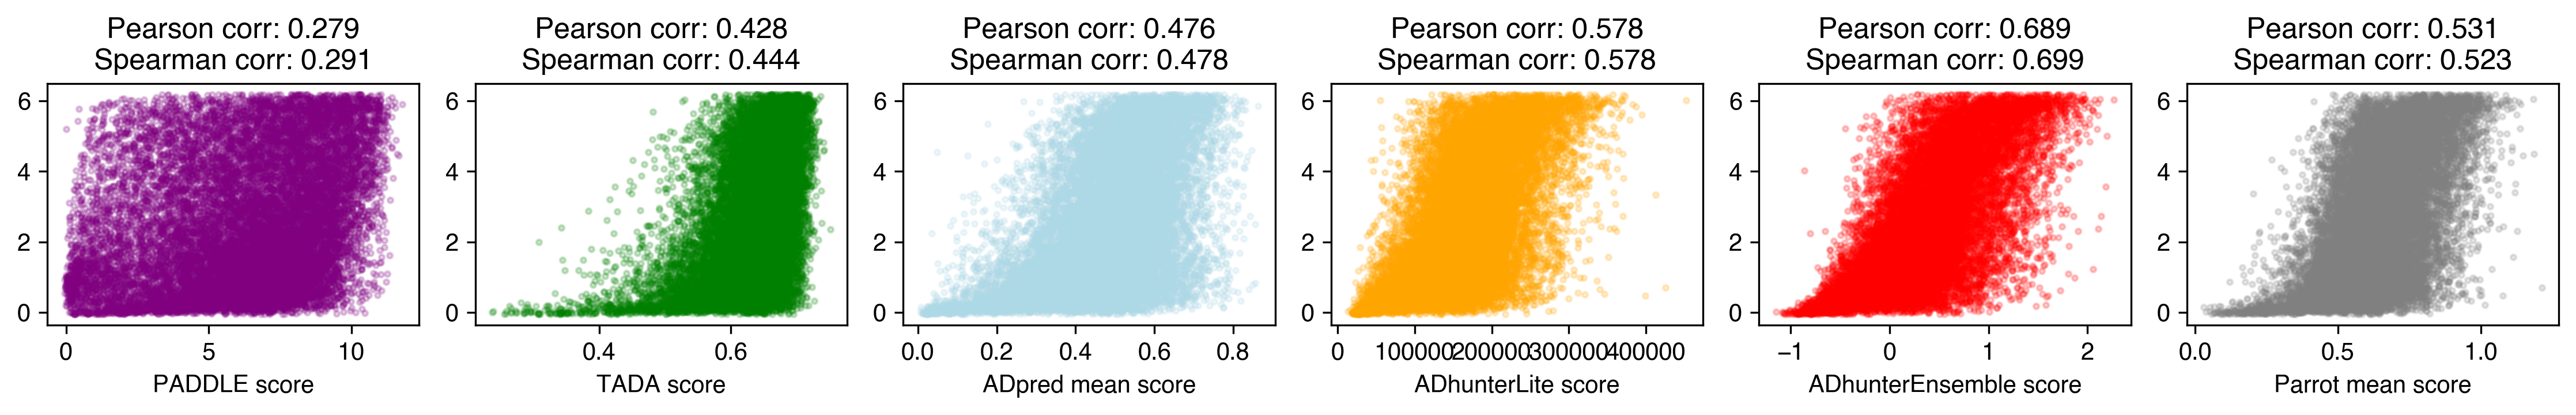

In [29]:
fig, axs = plt.subplots(1, 6, figsize=(15, 2.5))

# for i, col in enumerate(['paddle_no_SS_merged', 'tada', 'adpred', 'adhunter', 'adhunter_ensemble']): 

# paddle_no_SS_merged
col='paddle'
axs[0].scatter(all_merged['paddle_max_value'], 
                  all_merged['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged['paddle_max_value'], all_merged['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged['paddle_max_value'], all_merged['Activity'])
axs[0].set_xlabel('PADDLE score')
axs[0].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# tada
col='tada'
axs[1].scatter(all_merged['tada_max_value'], 
                  all_merged['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged['tada_max_value'], all_merged['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged['tada_max_value'], all_merged['Activity'])
axs[1].set_xlabel('TADA score')
axs[1].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# adpred
col='adpred'
axs[2].scatter(all_merged['adpred_mean_value'], 
                  all_merged['Activity'],
                  alpha=0.2,
                s=5,
                  color=color_dict[col])
pearson_corr, pearson_p = pearsonr(all_merged['adpred_mean_value'], all_merged['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged['adpred_mean_value'], all_merged['Activity'])
axs[2].set_xlabel(f'ADpred mean score')
axs[2].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# adhunter
col='adhunter'
axs[3].scatter(all_merged['adhunter_max_value'], 
                  all_merged['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged['adhunter_max_value'], all_merged['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged['adhunter_max_value'], all_merged['Activity'])
axs[3].set_xlabel('ADhunterLite score')
axs[3].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# adhunter ensemble
col='adhunter_ensemble'
axs[4].scatter(all_merged['adhunter_ensemble_max_value'], 
                  all_merged['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged['adhunter_ensemble_max_value'], all_merged['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged['adhunter_ensemble_max_value'], all_merged['Activity'])
axs[4].set_xlabel('ADhunterEnsemble score')
axs[4].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# Parrot preds - all six
axs[5].scatter(all_merged[f'parrot_mean_value_all_six'], 
                    all_merged['Activity'],
                    alpha=0.2,
                    s=5,
                    color='grey')
pearson_corr, pearson_p = pearsonr(all_merged[f'parrot_mean_value_all_six'], 
                                    all_merged['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged[f'parrot_mean_value_all_six'], 
                                        all_merged['Activity'])
axs[5].set_xlabel(f'Parrot mean score')
axs[5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

fig.tight_layout()

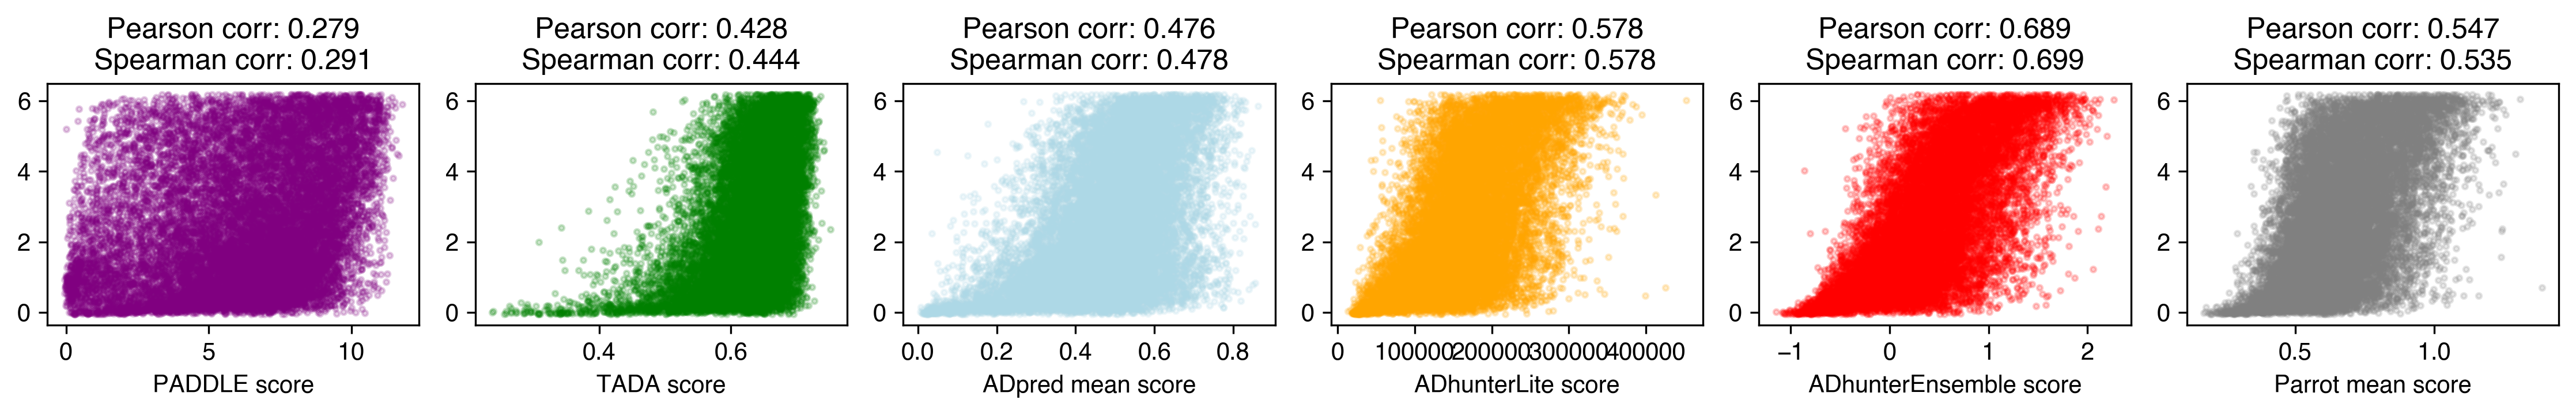

In [30]:
fig, axs = plt.subplots(1, 6, figsize=(15, 2.5))

# for i, col in enumerate(['paddle_no_SS_merged', 'tada', 'adpred', 'adhunter', 'adhunter_ensemble']): 

# paddle_no_SS_merged
col='paddle'
axs[0].scatter(all_merged_regression['paddle_max_value'], 
                  all_merged_regression['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged_regression['paddle_max_value'], all_merged_regression['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged_regression['paddle_max_value'], all_merged_regression['Activity'])
axs[0].set_xlabel('PADDLE score')
axs[0].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# tada
col='tada'
axs[1].scatter(all_merged_regression['tada_max_value'], 
                  all_merged_regression['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged_regression['tada_max_value'], all_merged_regression['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged_regression['tada_max_value'], all_merged_regression['Activity'])
axs[1].set_xlabel('TADA score')
axs[1].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# adpred
col='adpred'
axs[2].scatter(all_merged_regression['adpred_mean_value'], 
                  all_merged_regression['Activity'],
                  alpha=0.2,
                s=5,
                  color=color_dict[col])
pearson_corr, pearson_p = pearsonr(all_merged_regression['adpred_mean_value'], all_merged_regression['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged_regression['adpred_mean_value'], all_merged_regression['Activity'])
axs[2].set_xlabel(f'ADpred mean score')
axs[2].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# adhunter
col='adhunter'
axs[3].scatter(all_merged_regression['adhunter_max_value'], 
                  all_merged_regression['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged_regression['adhunter_max_value'], all_merged_regression['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged_regression['adhunter_max_value'], all_merged_regression['Activity'])
axs[3].set_xlabel('ADhunterLite score')
axs[3].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# adhunter ensemble
col='adhunter_ensemble'
axs[4].scatter(all_merged_regression['adhunter_ensemble_max_value'], 
                  all_merged_regression['Activity'], 
                  alpha=0.2,
                    s=5, 
                  color=color_dict[col])

pearson_corr, pearson_p = pearsonr(all_merged_regression['adhunter_ensemble_max_value'], all_merged_regression['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged_regression['adhunter_ensemble_max_value'], all_merged_regression['Activity'])
axs[4].set_xlabel('ADhunterEnsemble score')
axs[4].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


# Parrot preds - all six
axs[5].scatter(all_merged_regression[f'parrot_mean_value_all_six'], 
                    all_merged_regression['Activity'],
                    alpha=0.2,
                    s=5,
                    color='grey')
pearson_corr, pearson_p = pearsonr(all_merged_regression[f'parrot_mean_value_all_six'], 
                                    all_merged_regression['Activity'])
spearman_corr, spearman_p = spearmanr(all_merged_regression[f'parrot_mean_value_all_six'], 
                                        all_merged_regression['Activity'])
axs[5].set_xlabel(f'Parrot mean score')
axs[5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

fig.tight_layout()

In [39]:
color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_ensemble' : 'red',
    'adhunter' : 'orange', 
    'paddle' : 'purple' 
}

def make_scatterplot_regression():
    fig, axs = plt.subplots(2, 6, figsize=(15, 5))

    for i, col in enumerate(['paddle', 'tada', 'adpred', 'adhunter', 'adhunter_ensemble']): 
        axs[0, i].scatter(all_merged[f'{col}_max_value'], 
                        all_merged['Activity'], 
                        alpha=0.2, 
                        s=5,
                        color=color_dict[col])

        pearson_corr, pearson_p = pearsonr(all_merged[f'{col}_max_value'], 
                                        all_merged['Activity'])
        spearman_corr, spearman_p = spearmanr(all_merged[f'{col}_max_value'], 
                                            all_merged['Activity'])
        axs[0, i].set_xlabel(f'{col}_max_value')
        axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

        axs[1, i].scatter(all_merged[f'{col}_mean_value'], 
                        all_merged['Activity'],
                        alpha=0.2,
                        s=5,
                        color=color_dict[col])
        pearson_corr, pearson_p = pearsonr(all_merged[f'{col}_mean_value'], 
                                        all_merged['Activity'])
        spearman_corr, spearman_p = spearmanr(all_merged[f'{col}_mean_value'], 
                                            all_merged['Activity'])
        axs[1, i].set_xlabel(f'{col}_mean_value')
        axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    # Parrot preds - all six
    axs[0, 5].scatter(all_merged[f'parrot_max_value_all_six'], 
                        all_merged['Activity'], 
                        alpha=0.1, s=5,
                        color='grey')

    pearson_corr, pearson_p = pearsonr(all_merged[f'parrot_max_value_all_six'], 
                                        all_merged['Activity'])
    spearman_corr, spearman_p = spearmanr(all_merged[f'parrot_max_value_all_six'], 
                                            all_merged['Activity'])
    axs[0, 5].set_xlabel(f'parrot_pred_max_value\nall_six')
    axs[0, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, 5].scatter(all_merged[f'parrot_mean_value_all_six'], 
                        all_merged['Activity'],
                        alpha=0.1, s=5,
                        color='grey')
    pearson_corr, pearson_p = pearsonr(all_merged[f'parrot_mean_value_all_six'], 
                                        all_merged['Activity'])
    spearman_corr, spearman_p = spearmanr(all_merged[f'parrot_mean_value_all_six'], 
                                            all_merged['Activity'])
    axs[1, 5].set_xlabel(f'parrot_pred_mean_value\nall_six')
    axs[1, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    fig.tight_layout()
    # plt.savefig(f"../figures/{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
    # plt.savefig(f"../figures/{screen}_scatter_plots.png", format='png', bbox_inches='tight')


color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_ensemble' : 'red',
    'adhunter' : 'orange', 
    'paddle' : 'purple' 
}

def make_scatterplot():
    fig, axs = plt.subplots(2, 6, figsize=(15, 5))

    for i, col in enumerate(['paddle', 'tada', 'adpred', 'adhunter', 'adhunter_ensemble']): 
        axs[0, i].scatter(all_merged[f'{col}_max_value'], 
                        all_merged['Activity'], 
                        alpha=0.2, 
                        s=5,
                        color=color_dict[col])

        pearson_corr, pearson_p = pearsonr(all_merged[f'{col}_max_value'], 
                                        all_merged['Activity'])
        spearman_corr, spearman_p = spearmanr(all_merged[f'{col}_max_value'], 
                                            all_merged['Activity'])
        axs[0, i].set_xlabel(f'{col}_max_value')
        axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

        axs[1, i].scatter(all_merged[f'{col}_mean_value'], 
                        all_merged['Activity'],
                        alpha=0.2,
                        s=5,
                        color=color_dict[col])
        pearson_corr, pearson_p = pearsonr(all_merged[f'{col}_mean_value'], 
                                        all_merged['Activity'])
        spearman_corr, spearman_p = spearmanr(all_merged[f'{col}_mean_value'], 
                                            all_merged['Activity'])
        axs[1, i].set_xlabel(f'{col}_mean_value')
        axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    # Parrot preds - all six
    axs[0, 5].scatter(all_merged[f'parrot_max_value_all_six'], 
                        all_merged['Activity'], 
                        alpha=0.1, s=5,
                        color='grey')

    pearson_corr, pearson_p = pearsonr(all_merged[f'parrot_max_value_all_six'], 
                                        all_merged['Activity'])
    spearman_corr, spearman_p = spearmanr(all_merged[f'parrot_max_value_all_six'], 
                                            all_merged['Activity'])
    axs[0, 5].set_xlabel(f'parrot_pred_max_value\nall_six')
    axs[0, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, 5].scatter(all_merged[f'parrot_mean_value_all_six'], 
                        all_merged['Activity'],
                        alpha=0.1, s=5,
                        color='grey')
    pearson_corr, pearson_p = pearsonr(all_merged[f'parrot_mean_value_all_six'], 
                                        all_merged['Activity'])
    spearman_corr, spearman_p = spearmanr(all_merged[f'parrot_mean_value_all_six'], 
                                            all_merged['Activity'])
    axs[1, 5].set_xlabel(f'parrot_pred_mean_value\nall_six')
    axs[1, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    fig.tight_layout()
    # plt.savefig(f"../figures/{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
    # plt.savefig(f"../figures/{screen}_scatter_plots.png", format='png', bbox_inches='tight')

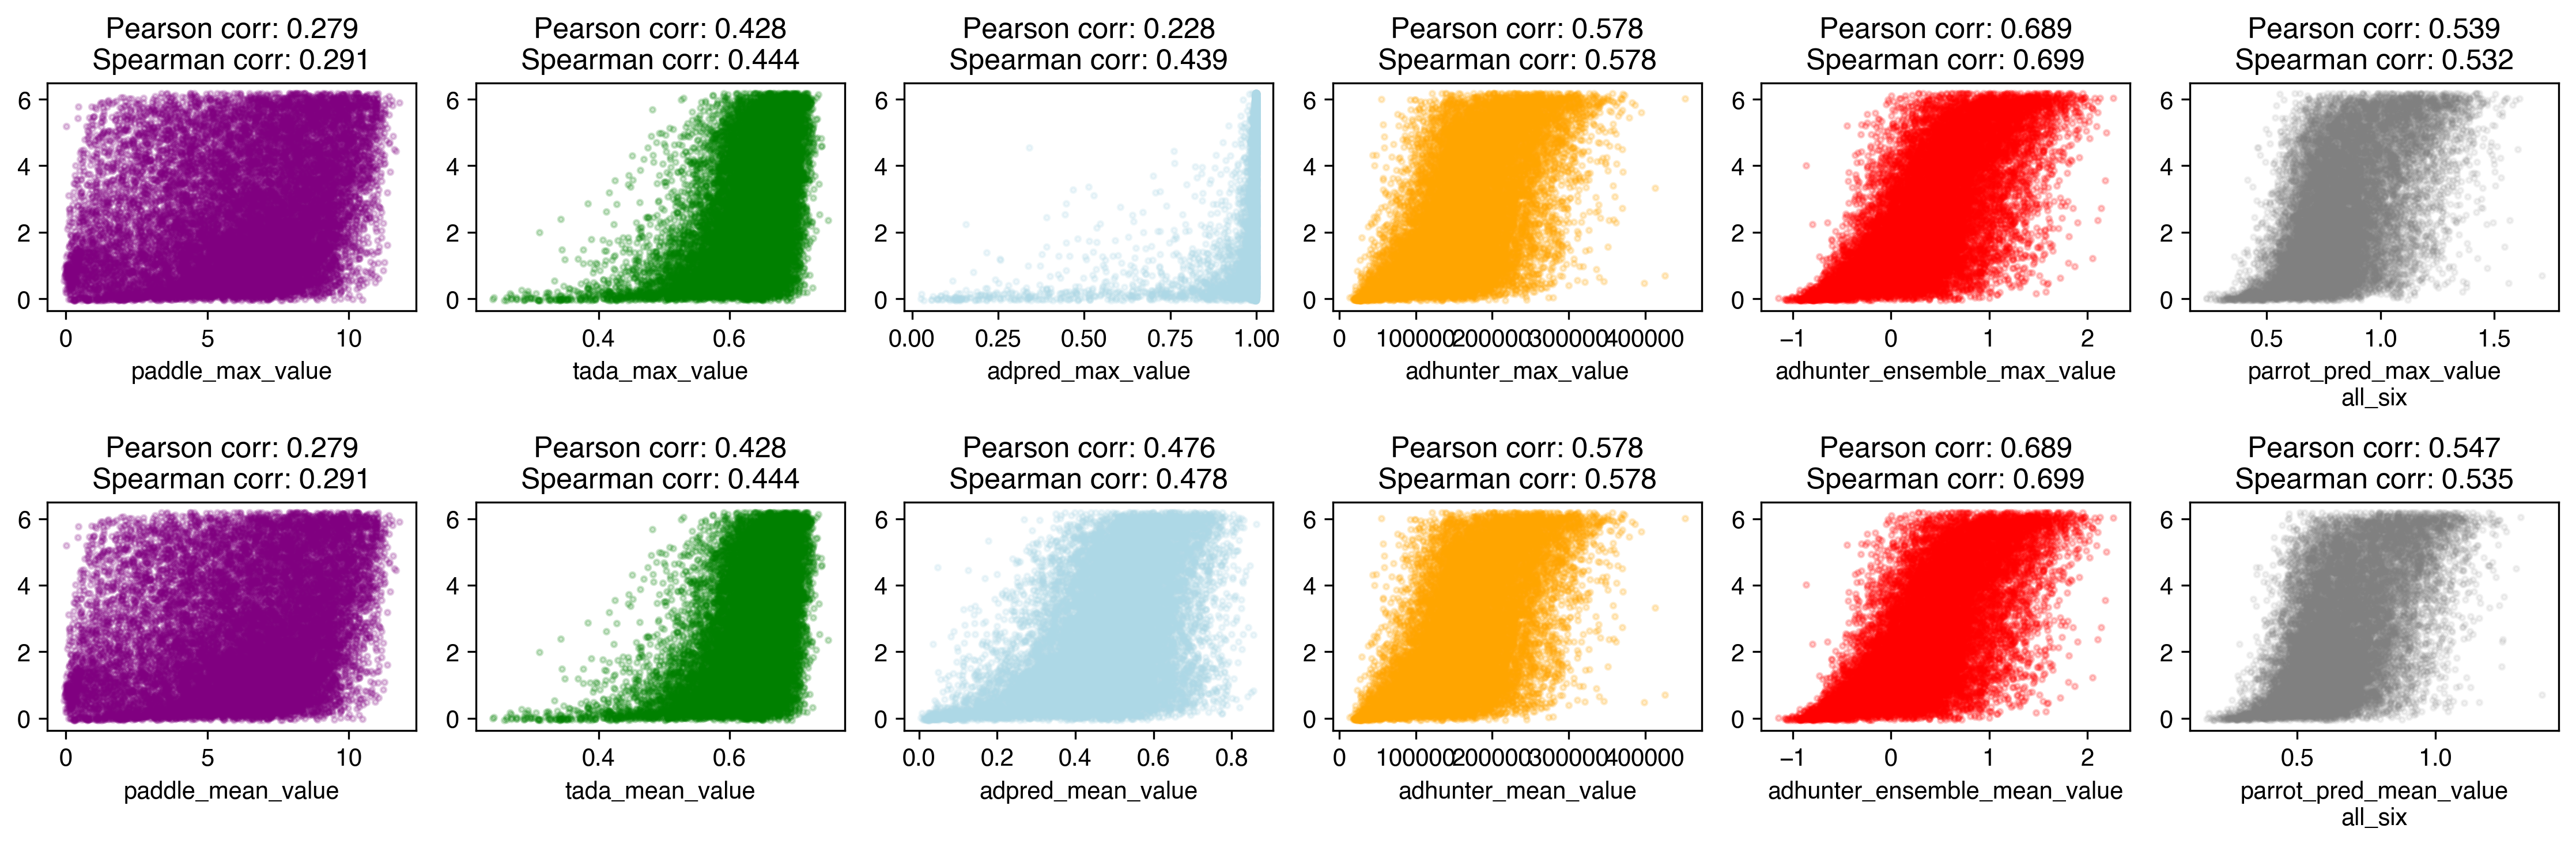

In [37]:
make_scatterplot_regression()

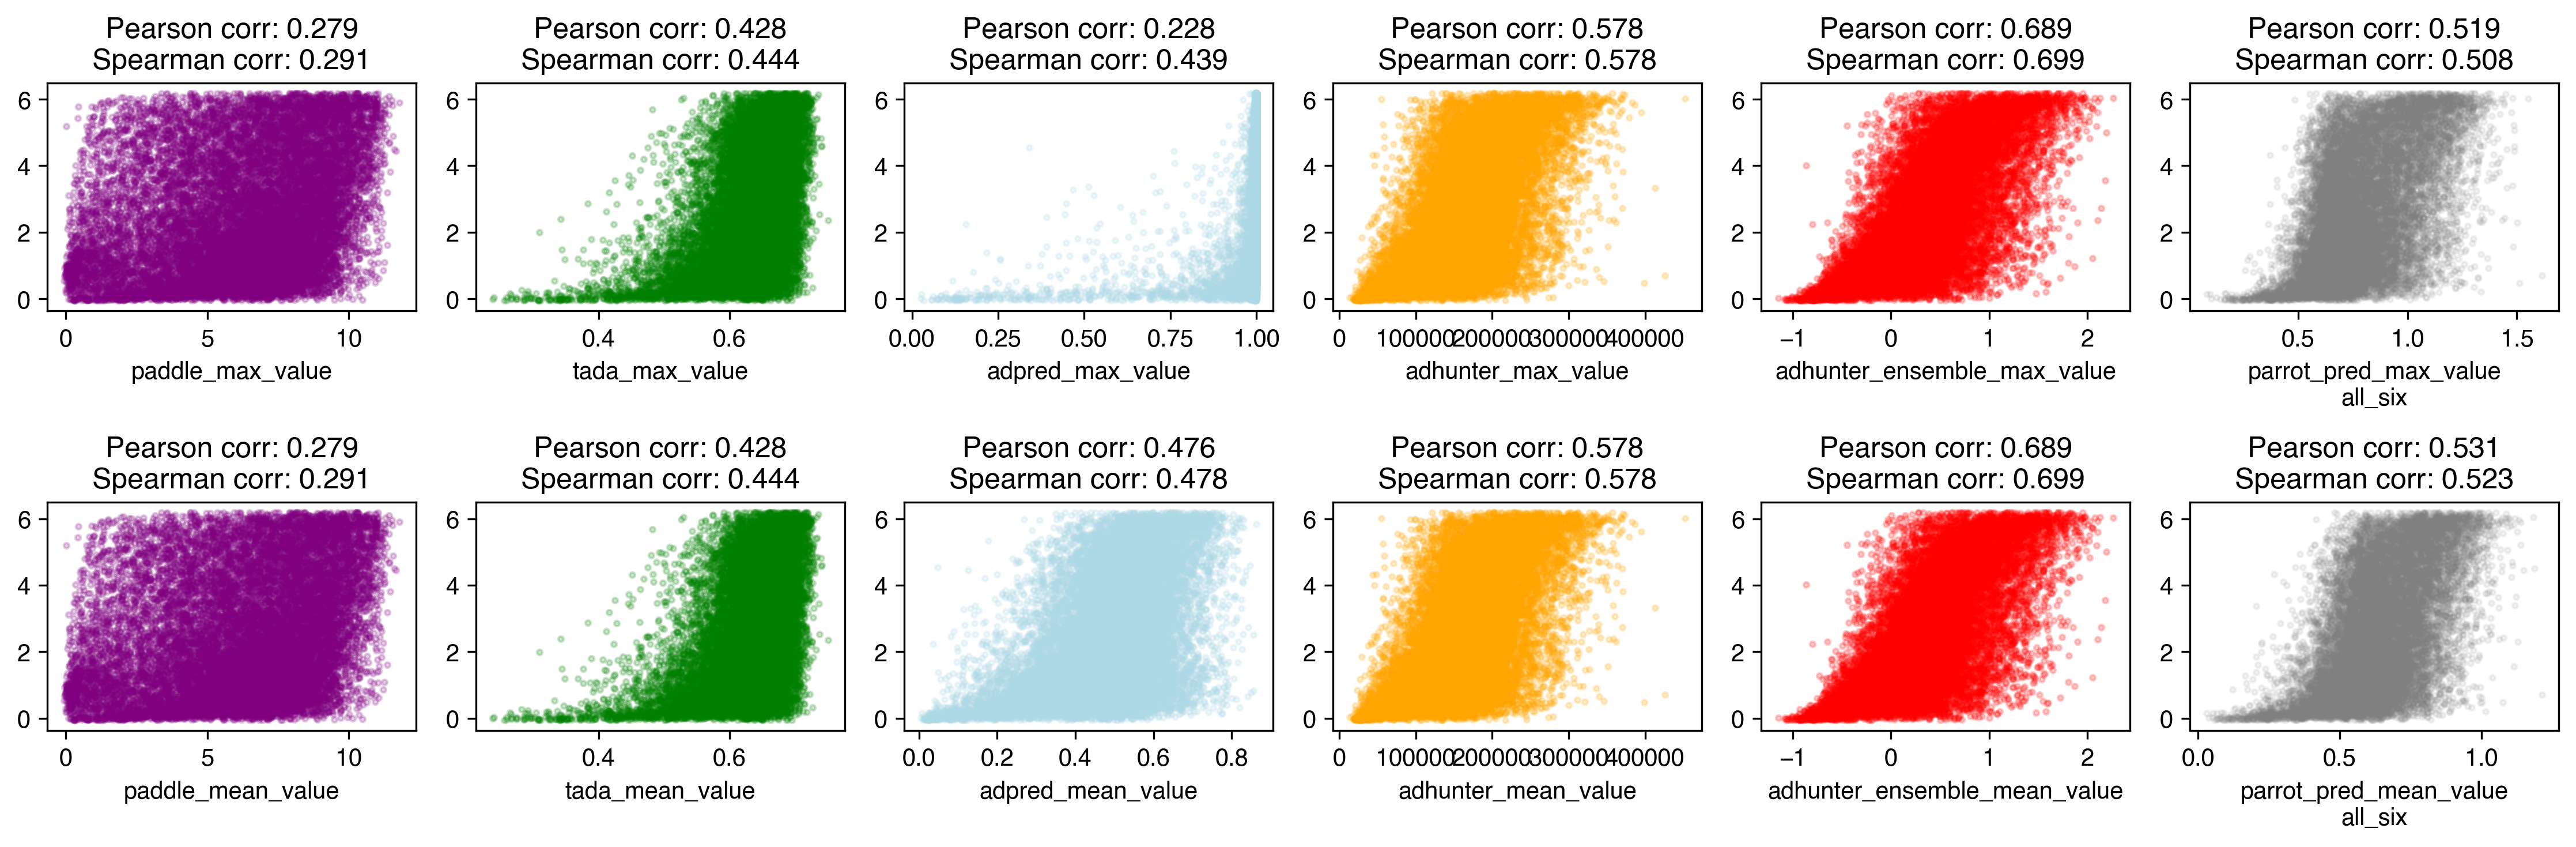

In [40]:
make_scatterplot()